In [1]:
# Configuración general
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEMILLA = 42   # para que los datos sintéticos y la partición sean reproducibles

## 1. Tarea de Machine Learning

- **Tipo de aprendizaje:** supervisado.
- **Tarea:** regresión (la variable a predecir es un número continuo).
- **Variable de entrada (X):** capital acumulado invertido, en millones de USD.
- **Variable de salida (y):** retorno esperado, en millones de USD.

**Por qué esta tarea:** en el Bloque de búsqueda el proyecto avanza por fases y en cada una acumula más capital (0, 10, 35, 75, 90 y 150 M USD). Pero la ruta solo nos dice cuánto cuesta llegar. Falta saber qué se obtiene a cambio, y no tenemos una fórmula exacta. Es un buen caso para aprender esa relación a partir de datos.

## 2. Datos: referenciales y sintéticos

Usamos dos fuentes y las mantenemos separadas:

1. **Datos referenciales (6 puntos):** el capital acumulado de cada estado del caso y un retorno esperado supuesto para cada uno.
2. **Datos sintéticos (60 puntos):** como seis puntos son muy pocos para entrenar y evaluar un modelo, generamos más a partir de la tendencia de los referenciales, más un ruido aleatorio de 8 M USD (supuesto) que imita la incertidumbre del negocio.

> Aviso: los datos sintéticos nacen de la tendencia de los referenciales, así que sirven para demostrar el pipeline y no aportan información nueva sobre el mundo real.

In [2]:
# DATOS REFERENCIALES (a partir del caso)
estados = ["S0", "S1", "S2", "S3", "S4", "META"]
capital_ref = np.array([[0], [10], [35], [75], [90], [150]])   # M USD (suma de costos del grafo)
retorno_ref = np.array([0, 8, 30, 70, 95, 165])                # retorno esperado (supuesto)

print("Datos referenciales:")
for e, c, r in zip(estados, capital_ref.ravel(), retorno_ref):
    print(f"  {e:<5} capital = {c:>3} M USD | retorno esperado = {r:>3} M USD")

Datos referenciales:
  S0    capital =   0 M USD | retorno esperado =   0 M USD
  S1    capital =  10 M USD | retorno esperado =   8 M USD
  S2    capital =  35 M USD | retorno esperado =  30 M USD
  S3    capital =  75 M USD | retorno esperado =  70 M USD
  S4    capital =  90 M USD | retorno esperado =  95 M USD
  META  capital = 150 M USD | retorno esperado = 165 M USD


In [3]:
# DATOS SINTÉTICOS: tendencia de los referenciales + ruido gaussiano
pendiente_ref, intercepto_ref = np.polyfit(capital_ref.ravel(), retorno_ref, 1)

rng = np.random.default_rng(SEMILLA)
capital_sint = rng.uniform(0, 150, size=60)
retorno_sint = pendiente_ref * capital_sint + intercepto_ref + rng.normal(0, 8, size=60)
retorno_sint = np.clip(retorno_sint, 0, None)       # un retorno no puede ser negativo

X = capital_sint.reshape(-1, 1)
y = retorno_sint

print(f"Tendencia base (de los referenciales): retorno = {pendiente_ref:.3f} * capital + ({intercepto_ref:.2f})")
print(f"Datos sintéticos generados: {len(y)} puntos | capital entre {X.min():.1f} y {X.max():.1f} M USD")

Tendencia base (de los referenciales): retorno = 1.103 * capital + (-4.87)
Datos sintéticos generados: 60 puntos | capital entre 1.1 y 146.3 M USD


## 3. Preparación: partición entrenamiento / prueba

Separamos el 25 % de los datos sintéticos para **probar** el modelo con puntos que no vio al entrenar. Así medimos qué tan bien generaliza y no solo qué tan bien memoriza.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEMILLA)
print("Entrenamiento:", len(y_train), "puntos | Prueba:", len(y_test), "puntos")

Entrenamiento: 45 puntos | Prueba: 15 puntos


## 4. Modelo elegido: regresión lineal dentro de un pipeline

**Modelo:** regresión lineal simple, `retorno = a * capital + b`, dentro de un `Pipeline` de scikit-learn con dos pasos: `StandardScaler` y `LinearRegression`.

**Por qué lo elegimos:**

- **La relación se ve lineal.** En los datos referenciales el retorno crece de forma casi proporcional al capital.
- **Es interpretable.** La pendiente `a` dice cuántos M USD de retorno se esperan por cada M USD adicional invertido, y eso se puede explicar a cualquiera.
- **Hay pocos datos.** Un modelo simple tiene menos riesgo de sobreajustarse (memorizar el ruido) que uno complejo.
- **El pipeline ordena el proceso.** `StandardScaler` normaliza la entrada y encadena preparación y modelo en un solo objeto, así evitamos errores al predecir. Con una sola variable no cambia las predicciones, pero deja el modelo listo para sumar variables (por ejemplo, el riesgo) más adelante.

In [5]:
modelo = make_pipeline(StandardScaler(), LinearRegression())
modelo.fit(X_train, y_train)          # entrenamiento

# Recuperamos la ecuación en las unidades originales (M USD)
escalador = modelo.named_steps["standardscaler"]
lineal = modelo.named_steps["linearregression"]
a = lineal.coef_[0] / escalador.scale_[0]
b = lineal.intercept_ - a * escalador.mean_[0]

print(f"Ecuación aprendida: retorno = {a:.3f} * capital + ({b:.2f})")
print(f"Interpretación: cada 1 M USD adicional de capital se asocia a {a:.2f} M USD de retorno esperado")

Ecuación aprendida: retorno = 1.076 * capital + (-3.79)
Interpretación: cada 1 M USD adicional de capital se asocia a 1.08 M USD de retorno esperado


## 5. Evaluación y sustento del modelo

Medimos el error con tres métricas:

- **R²:** qué porción de la variación del retorno explica el modelo (1 es perfecto).
- **MAE:** error absoluto medio, en M USD. Es el error típico de una predicción.
- **RMSE:** como el MAE pero castiga más los errores grandes, también en M USD.

Además comparamos con un modelo más flexible (polinomio de grado 2) usando validación cruzada de 5 particiones. Si el polinomio no mejora de forma clara, nos quedamos con el modelo simple.

In [6]:
def metricas(nombre, X_, y_):
    pred = modelo.predict(X_)
    r2 = r2_score(y_, pred)
    mae = mean_absolute_error(y_, pred)
    rmse = mean_squared_error(y_, pred) ** 0.5
    print(f"{nombre:<26} R2 = {r2:.3f} | MAE = {mae:5.2f} M USD | RMSE = {rmse:5.2f} M USD")

metricas("Entrenamiento (sintético)", X_train, y_train)
metricas("Prueba (sintético)", X_test, y_test)
metricas("6 estados referenciales", capital_ref, retorno_ref)

print()
print("Comparación por validación cruzada (R2 medio de 5 particiones):")
candidatos = {
    "Lineal (elegido)": make_pipeline(StandardScaler(), LinearRegression()),
    "Polinomio grado 2": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
}
for nombre, m in candidatos.items():
    puntajes = cross_val_score(m, X, y, cv=5, scoring="r2")
    print(f"  {nombre:<18} R2 = {puntajes.mean():.3f} (+/- {puntajes.std():.3f})")

Entrenamiento (sintético)  R2 = 0.986 | MAE =  4.45 M USD | RMSE =  5.45 M USD
Prueba (sintético)         R2 = 0.976 | MAE =  5.91 M USD | RMSE =  6.74 M USD
6 estados referenciales    R2 = 0.993 | MAE =  4.15 M USD | RMSE =  4.76 M USD

Comparación por validación cruzada (R2 medio de 5 particiones):
  Lineal (elegido)   R2 = 0.982 (+/- 0.010)
  Polinomio grado 2  R2 = 0.982 (+/- 0.010)


**Lectura de los resultados:**

- El R² en prueba es alto y cercano al de entrenamiento: el modelo **generaliza** y no está sobreajustado.
- El error típico (MAE) ronda los 6 M USD, pequeño frente a un rango de retorno de 0 a 165 M USD.
- Sobre los 6 estados referenciales el modelo también se comporta bien, con errores de pocos M USD.
- El polinomio de grado 2 **no mejora de forma apreciable** a la regresión lineal. Si no gana precisión, no vale la pena la complejidad extra, así que mantenemos el modelo lineal.

*Cuidado con la lectura:* como los datos sintéticos se generaron a partir de una tendencia lineal, es esperable que un modelo lineal ajuste bien. Esto confirma que el pipeline funciona; no demuestra que en la realidad el retorno sea lineal.

## 6. Predicción para capitales que no están en el grafo

Usamos el modelo entrenado para estimar el retorno con montos intermedios que no corresponden a ningún estado del Bloque de búsqueda.

In [7]:
nuevos = np.array([[50], [120]])
pred = np.clip(modelo.predict(nuevos), 0, None)      # el retorno no puede ser negativo

for c, p in zip(nuevos.ravel(), pred):
    print(f"Con {c:>3} M USD -> retorno predicho: {p:6.1f} M USD | diferencia frente al capital: {p - c:+.1f} M USD")

Con  50 M USD -> retorno predicho:   50.0 M USD | diferencia frente al capital: +0.0 M USD
Con 120 M USD -> retorno predicho:  125.4 M USD | diferencia frente al capital: +5.4 M USD


## 7. Visualización interpretativa

El gráfico de la izquierda muestra el modelo contra los datos y contra la línea de **retorno = capital invertido** (la diagonal punteada). Donde la recta del modelo está por encima de esa diagonal, el proyecto recupera más de lo que invirtió; donde está por debajo, pierde. El de la derecha muestra los errores del modelo para comprobar que no tienen un patrón.

Punto de equilibrio estimado: 49.6 M USD de capital


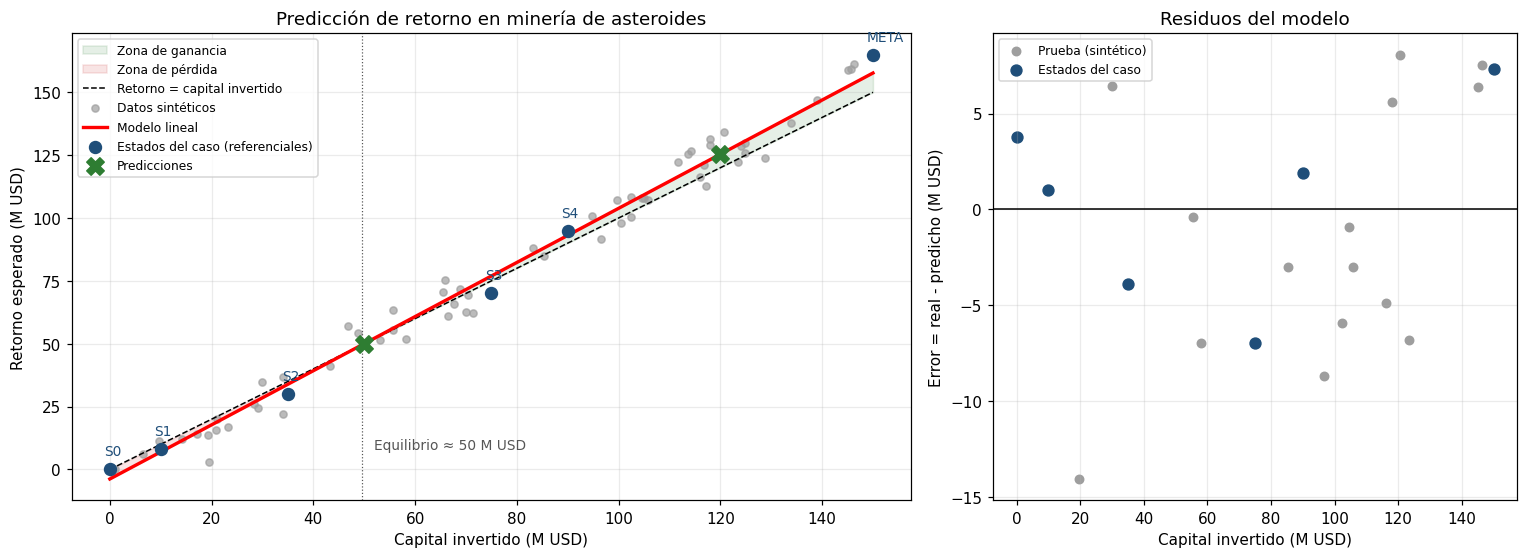

In [8]:
# Punto de equilibrio: capital donde el retorno predicho iguala al capital invertido
equilibrio = -b / (a - 1)

x = np.linspace(0, 150, 200)
y_modelo = a * x + b

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})

# --- Panel izquierdo: modelo e interpretación ---
ax1.fill_between(x, y_modelo, x, where=(y_modelo >= x), color="#2e7d32", alpha=0.12, label="Zona de ganancia")
ax1.fill_between(x, y_modelo, x, where=(y_modelo < x), color="#c62828", alpha=0.12, label="Zona de pérdida")
ax1.plot(x, x, "k--", lw=1, label="Retorno = capital invertido")
ax1.scatter(X, y, color="#9e9e9e", s=22, alpha=0.7, label="Datos sintéticos")
ax1.plot(x, y_modelo, "r-", lw=2.2, label="Modelo lineal")
ax1.scatter(capital_ref, retorno_ref, color="#1f4e79", s=60, zorder=5, label="Estados del caso (referenciales)")
for e, c, r in zip(estados, capital_ref.ravel(), retorno_ref):
    ax1.annotate(e, (c, r), textcoords="offset points", xytext=(-4, 9), fontsize=9, color="#1f4e79")
ax1.scatter(nuevos, pred, color="#2e7d32", marker="X", s=130, zorder=6, label="Predicciones")
ax1.axvline(equilibrio, color="#555", lw=0.8, ls=":")
ax1.annotate(f"Equilibrio ≈ {equilibrio:.0f} M USD", (equilibrio, 8), textcoords="offset points",
             xytext=(8, 0), fontsize=9, color="#555")
ax1.set_xlabel("Capital invertido (M USD)")
ax1.set_ylabel("Retorno esperado (M USD)")
ax1.set_title("Predicción de retorno en minería de asteroides")
ax1.legend(fontsize=8, loc="upper left")
ax1.grid(alpha=0.25)

# --- Panel derecho: residuos (error = real - predicho) ---
res_test = y_test - modelo.predict(X_test)
res_ref = retorno_ref - modelo.predict(capital_ref)
ax2.axhline(0, color="k", lw=1)
ax2.scatter(X_test, res_test, color="#9e9e9e", s=30, label="Prueba (sintético)")
ax2.scatter(capital_ref, res_ref, color="#1f4e79", s=50, label="Estados del caso")
ax2.set_xlabel("Capital invertido (M USD)")
ax2.set_ylabel("Error = real - predicho (M USD)")
ax2.set_title("Residuos del modelo")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()
print(f"Punto de equilibrio estimado: {equilibrio:.1f} M USD de capital")


### Conclusiones y limitaciones

- La tarea es **regresión supervisada**: predecir el retorno esperado a partir del capital acumulado.
- El pipeline `StandardScaler + LinearRegression` ajusta bien, generaliza a datos de prueba y es fácil de explicar.
- Con capital 0 la ecuación da un valor ligeramente negativo; no tiene sentido real, por eso las predicciones se acotan en 0 y el modelo solo se usa dentro del rango de 0 a 150 M USD.
- Los datos son referenciales y sintéticos, y los sintéticos derivan de los referenciales. **El modelo demuestra el flujo de trabajo; no es una herramienta para decidir inversiones reales.** Con datos históricos reales se podrían probar más variables (riesgo, fase tecnológica) y modelos más flexibles.